# Projet DermaMNIST · Sujet 3 : un outil de tri pour le médecin généraliste

**Groupe :** *(vos trois prénoms)*

## Sujet

DermaMNIST rassemble 10 015 images dermatoscopiques de lésions pigmentées de la peau (issues de la base HAM10000), réparties en 7 types et découpées en train (7 007 images), validation (1 003) et test (2 005). Un médecin généraliste photographie une lésion et doit décider s'il adresse son patient au dermatologue.

**Mission.** Les 7 types sont regroupés en deux catégories (déjà fait dans la cellule de données) : **« à adresser »** (mélanome, carcinome basocellulaire, kératose actinique / carcinome intraépithélial) et **« bénigne »** (les autres). Construire un outil qui rate le moins possible de lésions à adresser.

**Approche.** Un **Vision Transformer pré-entraîné** (par exemple un petit ViT de la bibliothèque `timm`), adapté avec **LoRA** (bibliothèque `peft`) par exemple ! Vous pouvez proposer une autre approche.

**Critère de réussite.** La sensibilité (part des lésions à adresser que l'outil détecte) pour un taux de fausses alertes que vous fixez à l'avance et justifiez. Indiquez aussi le nombre de paramètres entraînés, comparé à un fine-tuning total.

**Baseline.**
- La règle triviale « tout est bénin ».
- Le même ViT dont seule la dernière couche est entraînée.

## Consignes

- **Tout faire dans ce notebook.**
- **Sans IA** : pas de Copilot, de ChatGPT ni d'autre assistant. Vous en êtes capables ! Si besoin, venez me voir.
- **À 15 h, vous présenterez vos résultats** :
  1. Présenter l'objectif
  2. La stratégie que vous avez choisie
  3. Expliquer les différentes étapes que vous avez dû faire
  4. Expliquer les problèmes rencontrés
  5. Présenter vos résultats
  6. Les analyser et les critiquer
- **Comparez les performances obtenues à une baseline** (voir le sujet ci-dessus).

## Récupérer les données

La cellule ci-dessous télécharge DermaMNIST en 64×64 pixels (une seule fois), puis le charge en mémoire :

| Variable | Contenu |
|---|---|
| `X_train`, `X_val`, `X_test` | images, tableaux numpy `uint8` de forme `(N, 64, 64, 3)` |
| `y_train`, `y_val`, `y_test` | classe de chaque image, entier de 0 à 6 |
| `CLASSES` | nom de chaque classe |
| `yb_train`, `yb_val`, `yb_test` | 1 si la lésion est à adresser au dermatologue, 0 sinon |

Vos machines n'ont pas de GPU : mettez votre code au point sur un petit sous-échantillon, mesurez le temps d'une époque, puis seulement passez à plus de données.

In [22]:
%pip install -q numpy matplotlib requests

# ----- Outil de téléchargement (rien à modifier) -----
import os, hashlib
import requests

def telecharger(url, chemin, md5=None, sha256=None):
    """Télécharge url dans chemin, sauf si le fichier est déjà là."""
    if os.path.exists(chemin):
        print(f"Déjà présent : {chemin}")
        return
    os.makedirs(os.path.dirname(chemin), exist_ok=True)
    print(f"Téléchargement de {os.path.basename(chemin)} :", end=" ")
    empreinte = hashlib.md5() if md5 else hashlib.sha256()
    with requests.get(url, stream=True, timeout=60) as r:
        r.raise_for_status()
        total = int(r.headers.get("content-length", 0))
        recu, palier = 0, 0
        with open(chemin + ".part", "wb") as f:
            for bloc in r.iter_content(chunk_size=1 << 20):
                f.write(bloc)
                empreinte.update(bloc)
                recu += len(bloc)
                while total and recu * 100 // total >= palier:
                    print(f"{palier} %", end=" ")
                    palier += 10
    print()
    attendu = md5 or sha256
    if attendu and empreinte.hexdigest() != attendu:
        os.remove(chemin + ".part")
        raise RuntimeError("Fichier corrompu : relancez la cellule.")
    os.replace(chemin + ".part", chemin)

# ----- Chargement des données -----

import numpy as np

DATA_DIR = "data"
TAILLE = 64   # résolution des images : 28, 64, 128 ou 224 pixels (plus grand = plus lent)

FICHIERS = {   # nom du fichier et empreinte MD5 publiés par MedMNIST
    28:  ("dermamnist.npz",     "0744692d530f8e62ec473284d019b0c7"),   # 19,7 Mo
    64:  ("dermamnist_64.npz",  "b70a2f5635c6199aeaa28c31d7202e1f"),   # 100 Mo
    128: ("dermamnist_128.npz", "2defd784463fa5243564e855ed717de1"),   # 373 Mo
    224: ("dermamnist_224.npz", "8974907d8e169bef5f5b96bc506ae45d"),   # 1,1 Go
}
nom, md5 = FICHIERS[TAILLE]
chemin = os.path.join(DATA_DIR, nom)
telecharger(f"https://zenodo.org/records/10519652/files/{nom}?download=1", chemin, md5=md5)

donnees = np.load(chemin)
X_train, y_train = donnees["train_images"], donnees["train_labels"].ravel().astype(np.int64)
X_val,   y_val   = donnees["val_images"],   donnees["val_labels"].ravel().astype(np.int64)
X_test,  y_test  = donnees["test_images"],  donnees["test_labels"].ravel().astype(np.int64)

CLASSES = [
    "kératose actinique / carcinome intraépithélial",   # 0
    "carcinome basocellulaire",                         # 1
    "lésion kératosique bénigne",                       # 2
    "dermatofibrome",                                   # 3
    "mélanome",                                         # 4
    "nævus mélanocytaire (grain de beauté)",            # 5
    "lésion vasculaire",                                # 6
]

# Lésions à adresser au dermatologue : 0 (kératose actinique / carcinome intraépithélial),
# 1 (carcinome basocellulaire) et 4 (mélanome). Toutes les autres sont bénignes.
A_ADRESSER = [0, 1, 4]
yb_train = np.isin(y_train, A_ADRESSER).astype(np.int64)
yb_val   = np.isin(y_val,   A_ADRESSER).astype(np.int64)
yb_test  = np.isin(y_test,  A_ADRESSER).astype(np.int64)


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.
Déjà présent : data\dermamnist_64.npz


Train : (7007, 64, 64, 3) | Validation : (1003, 64, 64, 3) | Test : (2005, 64, 64, 3)

Classe                                              train    val   test
0  kératose actinique / carcinome intraépithélial     228     33     66
1  carcinome basocellulaire                           359     52    103
2  lésion kératosique bénigne                         769    110    220
3  dermatofibrome                                      80     12     23
4  mélanome                                           779    111    223
5  nævus mélanocytaire (grain de beauté)             4693    671   1341
6  lésion vasculaire                                   99     14     29

Lésions à adresser (train) : 1366 sur 7007 (19.5%)
Lésions à adresser (val) : 196 sur 1003 (19.5%)
Lésions à adresser (test) : 392 sur 2005 (19.6%)


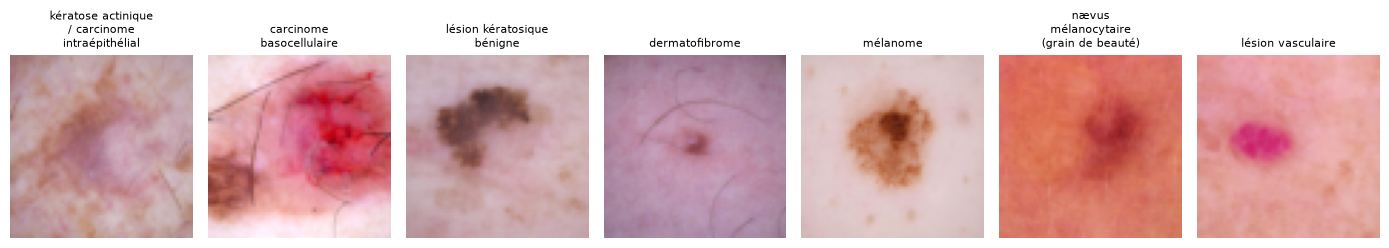

In [23]:
import textwrap
import matplotlib.pyplot as plt

print("Train :", X_train.shape, "| Validation :", X_val.shape, "| Test :", X_test.shape)
print()
print(f"{'Classe':<50}{'train':>7}{'val':>7}{'test':>7}")
for c, nom in enumerate(CLASSES):
    print(f"{c}  {nom:<47}{(y_train == c).sum():>7}{(y_val == c).sum():>7}{(y_test == c).sum():>7}")
print()
for nom_split, yb in [("train", yb_train), ("val", yb_val), ("test", yb_test)]:
    print(f"Lésions à adresser ({nom_split}) : {yb.sum()} sur {len(yb)} ({yb.mean():.1%})")

fig, axes = plt.subplots(1, 7, figsize=(14, 3))
for c, ax in enumerate(axes):
    i = np.flatnonzero(y_train == c)[0]
    ax.imshow(X_train[i])
    ax.set_title("\n".join(textwrap.wrap(CLASSES[c], 18)), fontsize=8)
    ax.axis("off")
plt.tight_layout()
plt.show()

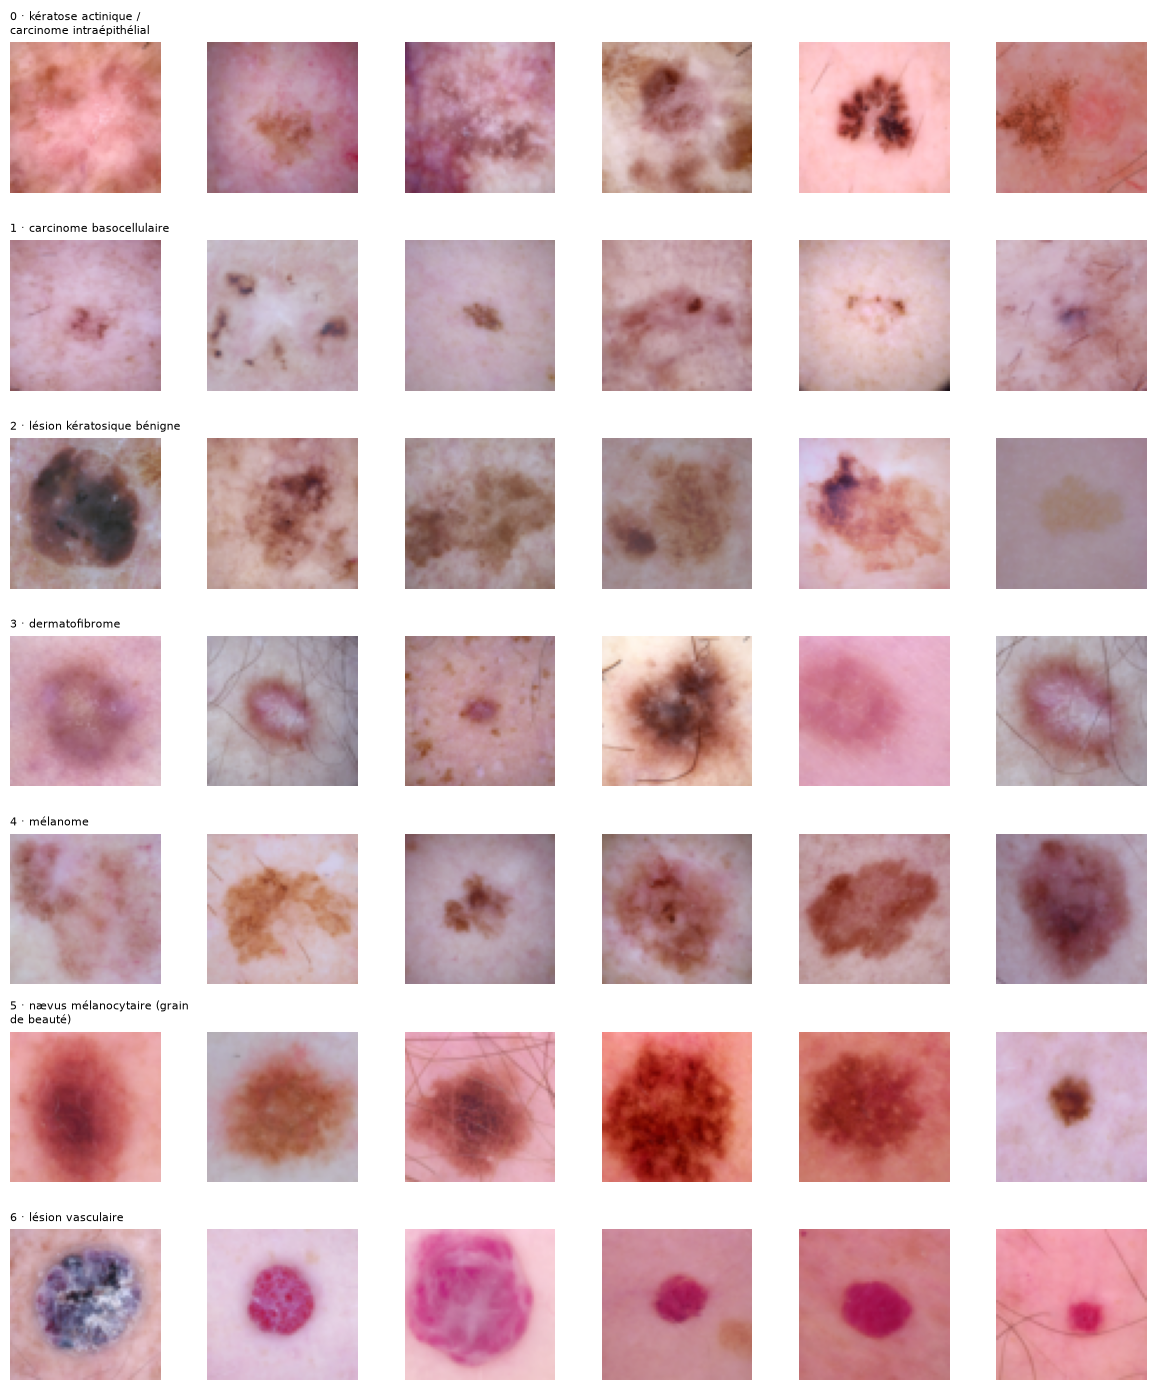

In [24]:
N_PAR_CLASSE = 6
fig, axes = plt.subplots(len(CLASSES), N_PAR_CLASSE, figsize=(2 * N_PAR_CLASSE, 2 * len(CLASSES)))
rng = np.random.default_rng(0)
for c in range(len(CLASSES)):
    indices = np.flatnonzero(y_train == c)
    choisis = rng.choice(indices, size=min(N_PAR_CLASSE, len(indices)), replace=False)
    for j in range(N_PAR_CLASSE):
        ax = axes[c, j]
        ax.axis("off")
        if j < len(choisis):
            ax.imshow(X_train[choisis[j]])
    axes[c, 0].set_title("\n".join(textwrap.wrap(f"{c} · {CLASSES[c]}", 30)), fontsize=8, loc="left")
plt.tight_layout()
plt.show()


## Votre travail

### Importation et chargement du modèle Transformer

In [25]:
%pip install -q timm peft scikit-learn

import torch
import torch.nn.functional as F
import timm
from peft import LoraConfig, get_peft_model
from sklearn.metrics import recall_score
import time

# Chargement du modèle Transformer pré-entraîné (ex: ViT miniature)
# pretrained=True récupère les poids de la vision générale
vit_modele = timm.create_model('vit_tiny_patch16_224', pretrained=True, num_classes=1) 
# Note : num_classes=1 car nous faisons une classification binaire (0 = bénin, 1 = à adresser)


[notice] A new release of pip is available: 26.1.2 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


### Normalisation et Tensor

In [26]:
from torchvision import transforms

transformations_images = transforms.Compose([
    transforms.ToPILImage(),                    # Convertit le tableau numpy en image PIL
    transforms.Resize((224, 224)),              # Redimensionne en 224x224 pixels
    transforms.ToTensor(),                      # Convertit en Tenseur PyTorch
    transforms.Normalize(                       # Normalisation
        mean=[0.485, 0.456, 0.406], 
        std=[0.229, 0.224, 0.225]
    )
])

### Application aux données de test

In [27]:
def preparer_donnees(X):
    # X est de forme (N, 64, 64, 3)
    liste_tenseurs = []
    for img in X:
        t = transformations_images(img) # Applique Resize -> Tenseur -> Normalisation
        liste_tenseurs.append(t)
    return torch.stack(liste_tenseurs) # Empile pour faire un gros Tenseur PyTorch de forme (N, 3, 224, 224)

# Préparation des tenseurs finaux prêts pour le modèle
X_train_tensors = preparer_donnees(X_train)
X_val_tensors = preparer_donnees(X_val)

print("Forme des tenseurs d'entraînement prêts :", X_train_tensors.shape)

Forme des tenseurs d'entraînement prêts : torch.Size([7007, 3, 224, 224])


### Application de LoRA

In [ ]:
# Configuration LoRA (identique à la logique vue en cours : rang r=8, alpha=16)
config = LoraConfig(r=8, lora_alpha=16,target_modules=["qkv"]
)

# Application de LoRA au modèle ViT
vit_modele = get_peft_model(vit_modele, config)

# Vérification du nombre de poids entraînables
vit_modele.print_trainable_parameters()

trainable params: 73,728 || all params: 5,598,337 || trainable%: 1.3170


### Optimiseur Adam

In [29]:
# Sélection exclusive des poids entraînables
entrainables = [p for p in vit_modele.parameters() if p.requires_grad]

# Détection du processeur ou passage sur GPU si disponible
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vit_modele.to(device)

print(f"Modèle prêt et chargé sur : {device}")

Modèle prêt et chargé sur : cpu


### Entrainement

Époque 1/5 -> Perte Train: 0.438 | Perte Val: 0.408 | Sensibilité Val: 66.3%
Époque 2/5 -> Perte Train: 0.322 | Perte Val: 0.342 | Sensibilité Val: 53.1%
Époque 3/5 -> Perte Train: 0.246 | Perte Val: 0.343 | Sensibilité Val: 37.2%
Époque 4/5 -> Perte Train: 0.176 | Perte Val: 0.424 | Sensibilité Val: 43.4%
Époque 5/5 -> Perte Train: 0.117 | Perte Val: 0.447 | Sensibilité Val: 51.5%


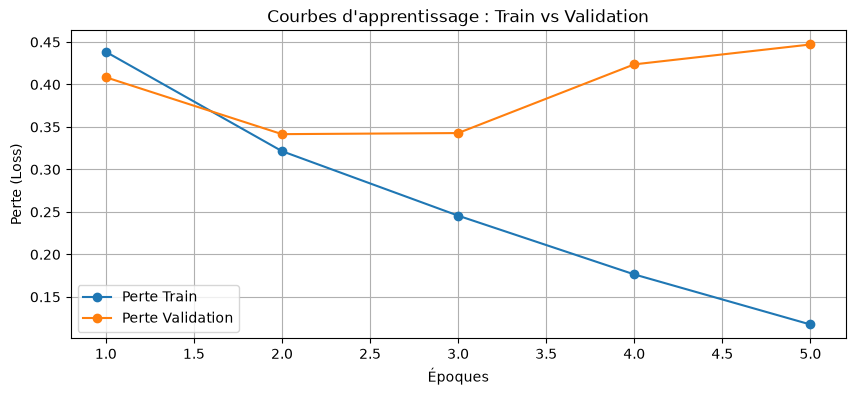

In [30]:
# Préparation de la validation
X_val_tensor = X_val_tensors.to(device)
yb_val_tensor = torch.tensor(yb_val, dtype=torch.float32).to(device)

# Utilisation d'AdamW avec un léger weight_decay pour lutter contre l'overfitting (vu au J4)
optimizer = torch.optim.AdamW(entrainables, lr=0.0005, weight_decay=0.01)

# Listes pour stocker l'historique des courbes
historique_perte_train = []
historique_perte_val = []
historique_sensibilite_val = []

epochs = 5
for epoque in range(epochs):
    # --- PHASE D'ENTRAÎNEMENT ---
    vit_modele.train() # Active le mode entraînement
    total_perte_train = 0.0
    ordre = torch.randperm(len(X_sub)).tolist()
    
    for d in range(0, len(ordre), 8):
        idx = ordre[d:d+8]
        inputs = X_sub[idx].to(device)
        cibles = yb_sub[idx].to(device)
        
        scores = vit_modele(inputs).squeeze(-1)
        perte = F.binary_cross_entropy_with_logits(scores, cibles)
        
        optimizer.zero_grad()
        perte.backward()
        optimizer.step()
        
        total_perte_train += perte.item() * len(idx)
        
    perte_train_moyenne = total_perte_train / len(X_sub)
    historique_perte_train.append(perte_train_moyenne)
    
    # --- PHASE DE VALIDATION ---
    vit_modele.eval() # Désactive le Dropout pour l'évaluation
    with torch.no_grad():
        # Calcul sur tout le jeu de validation
        scores_val = vit_modele(X_val_tensor).squeeze(-1)
        perte_val = F.binary_cross_entropy_with_logits(scores_val, yb_val_tensor).item()
        historique_perte_val.append(perte_val)
        
        # Calcul de la précision / sensibilité (Rappel)
        probas_val = torch.sigmoid(scores_val)
        preds_val = (probas_val >= 0.5).int().cpu().numpy()
        sensibilite_val = recall_score(yb_val, preds_val, zero_division=0)
        historique_sensibilite_val.append(sensibilite_val)
        
    print(f"Époque {epoque + 1}/{epochs} -> Perte Train: {perte_train_moyenne:.3f} | Perte Val: {perte_val:.3f} | Sensibilité Val: {sensibilite_val:.1%}")

# --- AFFICHAGE DES COURBES D'APPRENTISSAGE ---
plt.figure(figsize=(10, 4))
plt.plot(range(1, epochs + 1), historique_perte_train, label="Perte Train", marker='o')
plt.plot(range(1, epochs + 1), historique_perte_val, label="Perte Validation", marker='o')
plt.xlabel("Époques")
plt.ylabel("Perte (Loss)")
plt.title("Courbes d'apprentissage : Train vs Validation")
plt.legend()
plt.grid(True)
plt.show()

Overfiting flagrant, correction = augmentation de l'échantillon

In [31]:
yb_train_tensor = torch.tensor(yb_train, dtype=torch.float32)
yb_val_tensor = torch.tensor(yb_val, dtype=torch.float32)

print("Tenseur d'entraînement prêt :", X_train_tensors.shape)

Tenseur d'entraînement prêt : torch.Size([7007, 3, 224, 224])


In [ ]:
# Chargement d'un Transformer léger pré-entraîné
vit_modele = timm.create_model('vit_tiny_patch16_224', pretrained=True, num_classes=1)

# Application de LoRA (rang r=8, alpha=16 sur les modules d'attention qkv)
config = LoraConfig(r=8, lora_alpha=16, target_modules=["qkv"])
vit_modele = get_peft_model(vit_modele, config)
vit_modele.print_trainable_parameters()

trainable params: 73,728 || all params: 5,598,337 || trainable%: 1.3170


Époque 1/5 -> Perte Train: 0.348 | Perte Val: 0.307 | Sensibilité Val: 60.2% (212s)
Époque 2/5 -> Perte Train: 0.274 | Perte Val: 0.310 | Sensibilité Val: 47.4% (223s)
Époque 3/5 -> Perte Train: 0.232 | Perte Val: 0.278 | Sensibilité Val: 69.4% (221s)
Époque 4/5 -> Perte Train: 0.190 | Perte Val: 0.284 | Sensibilité Val: 56.1% (211s)
Époque 5/5 -> Perte Train: 0.152 | Perte Val: 0.285 | Sensibilité Val: 65.3% (211s)


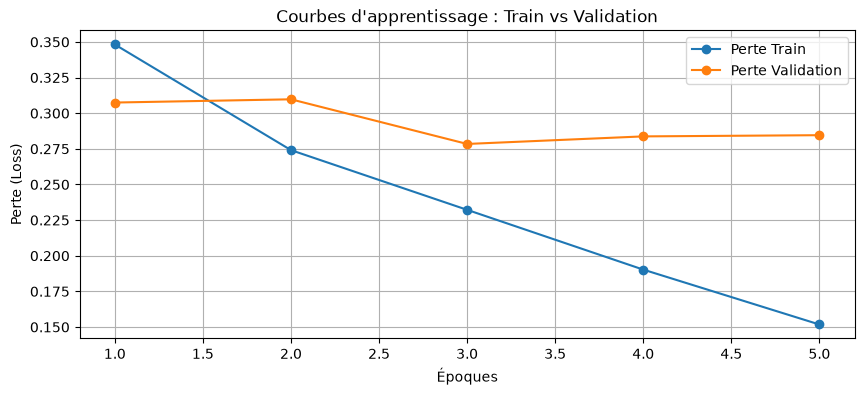

In [33]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vit_modele.to(device)

# Sélection des poids entraînables et configuration d'AdamW avec weight_decay (régularisation vue en cours)
entrainables = [p for p in vit_modele.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(entrainables, lr=0.0005, weight_decay=0.01)

X_val_dev = X_val_tensors.to(device)
yb_val_dev = yb_val_tensor.to(device)

historique_perte_train = []
historique_perte_val = []
historique_sensibilite_val = []

epochs = 5
for epoque in range(epochs):
    vit_modele.train()
    total_perte_train = 0.0
    ordre = torch.randperm(len(X_train_tensors)).tolist()
    debut = time.time()
    
    # Utilisation de tout le jeu d'entraînement (7 007 images) par paquets de 8
    for d in range(0, len(ordre), 8):
        idx = ordre[d:d+8]
        inputs = X_train_tensors[idx].to(device)
        cibles = yb_train_tensor[idx].to(device)
        
        scores = vit_modele(inputs).squeeze(-1)
        perte = F.binary_cross_entropy_with_logits(scores, cibles)
        
        optimizer.zero_grad()
        perte.backward()
        optimizer.step()
        
        total_perte_train += perte.item() * len(idx)
        
    perte_train_moyenne = total_perte_train / len(X_train_tensors)
    historique_perte_train.append(perte_train_moyenne)
    
    # Évaluation sur la validation à la fin de chaque époque
    vit_modele.eval()
    with torch.no_grad():
        scores_val = vit_modele(X_val_dev).squeeze(-1)
        perte_val = F.binary_cross_entropy_with_logits(scores_val, yb_val_dev).item()
        historique_perte_val.append(perte_val)
        
        probas_val = torch.sigmoid(scores_val)
        preds_val = (probas_val >= 0.5).int().cpu().numpy()
        sensibilite_val = recall_score(yb_val, preds_val, zero_division=0)
        historique_sensibilite_val.append(sensibilite_val)
        
    print(f"Époque {epoque + 1}/{epochs} -> Perte Train: {perte_train_moyenne:.3f} | Perte Val: {perte_val:.3f} | Sensibilité Val: {sensibilite_val:.1%} ({time.time() - debut:.0f}s)")

# Affichage des courbes d'apprentissage pour détecter l'overfitting
plt.figure(figsize=(10, 4))
plt.plot(range(1, epochs + 1), historique_perte_train, label="Perte Train", marker='o')
plt.plot(range(1, epochs + 1), historique_perte_val, label="Perte Validation", marker='o')
plt.xlabel("Époques")
plt.ylabel("Perte (Loss)")
plt.title("Courbes d'apprentissage : Train vs Validation")
plt.legend()
plt.grid(True)
plt.show()

### Nouvelle tentative en essayant maintenant de déterminer à quelle classe appartient une image

In [ ]:
import timm
from peft import LoraConfig, get_peft_model

#7 pathologies dermatologiques
vit_modele = timm.create_model('vit_tiny_patch16_224', pretrained=True, num_classes=7)

# Application de LoRA
config = LoraConfig(r=8, lora_alpha=16, target_modules=["qkv"])
vit_modele = get_peft_model(vit_modele, config)
vit_modele.print_trainable_parameters()

trainable params: 73,728 || all params: 5,599,495 || trainable%: 1.3167


In [35]:
import torch

# Utilisation des classes d'origine (y_train et y_val de 0 à 6)
y_train_tensor = torch.tensor(y_train, dtype=torch.long)
y_val_tensor = torch.tensor(y_val, dtype=torch.long)

Époque 1/5 -> Perte Train: 0.785 | Perte Val: 0.588 | Accuracy Val: 78.6% (447s)
Époque 2/5 -> Perte Train: 0.568 | Perte Val: 0.563 | Accuracy Val: 79.5% (285s)
Époque 3/5 -> Perte Train: 0.469 | Perte Val: 0.509 | Accuracy Val: 81.1% (330s)
Époque 4/5 -> Perte Train: 0.380 | Perte Val: 0.494 | Accuracy Val: 82.6% (338s)
Époque 5/5 -> Perte Train: 0.313 | Perte Val: 0.492 | Accuracy Val: 82.2% (259s)


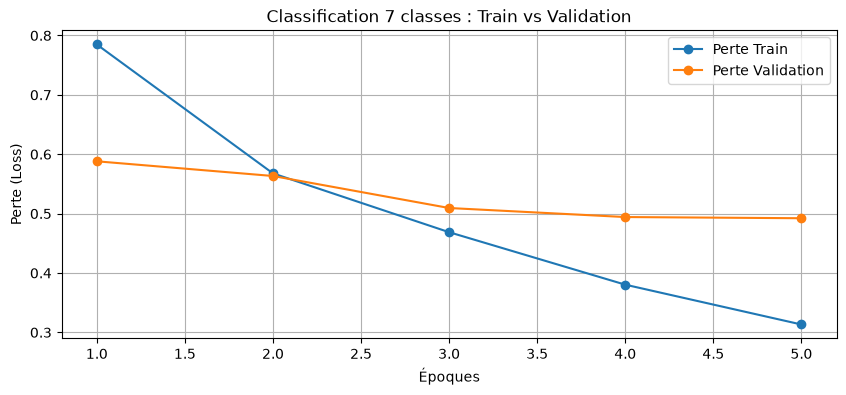

In [36]:
import torch.nn.functional as F
import matplotlib.pyplot as plt
from sklearn.metrics import accuracy_score
import time

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
vit_modele.to(device)

entrainables = [p for p in vit_modele.parameters() if p.requires_grad]
optimizer = torch.optim.AdamW(entrainables, lr=0.0005, weight_decay=0.01)

X_val_dev = X_val_tensors.to(device)
y_val_dev = y_val_tensor.to(device)

historique_perte_train = []
historique_perte_val = []
historique_acc_val = []

epochs = 5
for epoque in range(epochs):
    vit_modele.train()
    total_perte_train = 0.0
    ordre = torch.randperm(len(X_train_tensors)).tolist()
    debut = time.time()
    
    for d in range(0, len(ordre), 8):
        idx = ordre[d:d+8]
        inputs = X_train_tensors[idx].to(device)
        cibles = y_train_tensor[idx].to(device) # Labels de 0 à 6
        
        # Sortie brute (logits) de forme (batch_size, 7)
        scores = vit_modele(inputs)
        
        # Perte multi-classe (Cross Entropy)
        perte = F.cross_entropy(scores, cibles)
        
        optimizer.zero_grad()
        perte.backward()
        optimizer.step()
        
        total_perte_train += perte.item() * len(idx)
        
    perte_train_moyenne = total_perte_train / len(X_train_tensors)
    historique_perte_train.append(perte_train_moyenne)
    
    # Évaluation sur la validation
    vit_modele.eval()
    with torch.no_grad():
        scores_val = vit_modele(X_val_dev)
        perte_val = F.cross_entropy(scores_val, y_val_dev).item()
        historique_perte_val.append(perte_val)
        
        # Prédiction de la classe majoritaire (argmax)
        preds_val = torch.argmax(scores_val, dim=1).cpu().numpy()
        acc_val = accuracy_score(y_val, preds_val)
        historique_acc_val.append(acc_val)
        
    print(f"Époque {epoque + 1}/{epochs} -> Perte Train: {perte_train_moyenne:.3f} | Perte Val: {perte_val:.3f} | Accuracy Val: {acc_val:.1%} ({time.time() - debut:.0f}s)")

# Courbes d'apprentissage
plt.figure(figsize=(10, 4))
plt.plot(range(1, epochs + 1), historique_perte_train, label="Perte Train", marker='o')
plt.plot(range(1, epochs + 1), historique_perte_val, label="Perte Validation", marker='o')
plt.xlabel("Époques")
plt.ylabel("Perte (Loss)")
plt.title("Classification 7 classes : Train vs Validation")
plt.legend()
plt.grid(True)
plt.show()

In [37]:
from sklearn.metrics import classification_report, f1_score

# 1. Remettre le modèle en mode évaluation
vit_modele.eval()

# 2. Récupérer les prédictions sur tout le jeu de validation
with torch.no_grad():
    scores_val = vit_modele(X_val_dev)
    preds_val = torch.argmax(scores_val, dim=1).cpu().numpy()

# 3. Calculer les F1-scores par classe (average=None)
f1_par_classe = f1_score(y_val, preds_val, average=None, zero_division=0)

# 4. Afficher les résultats avec le nom de chaque classe
print(f"{'Classe':<50}{'F1-score':>10}")
print("-" * 60)
for c, nom in enumerate(CLASSES):
    print(f"{c}  {nom:<47}{f1_par_classe[c]:>10.3f}")

# (Optionnel) Un rapport complet incluant Précision, Rappel et F1 par classe :
print("\n--- Rapport détaillé ---")
print(classification_report(y_val, preds_val, target_names=CLASSES, zero_division=0))

Classe                                              F1-score
------------------------------------------------------------
0  kératose actinique / carcinome intraépithélial      0.452
1  carcinome basocellulaire                            0.732
2  lésion kératosique bénigne                          0.627
3  dermatofibrome                                      0.519
4  mélanome                                            0.545
5  nævus mélanocytaire (grain de beauté)               0.914
6  lésion vasculaire                                   0.846

--- Rapport détaillé ---
                                                precision    recall  f1-score   support

kératose actinique / carcinome intraépithélial       0.48      0.42      0.45        33
                      carcinome basocellulaire       0.68      0.79      0.73        52
                    lésion kératosique bénigne       0.77      0.53      0.63       110
                                dermatofibrome       0.47      0.58     